# Cópia

# Classificação de marcas de carros com imagens no Google Drive

Este notebook foi adaptado para usar **o seu dataset no Google Drive** e executar o fluxo completo:

1. montar o Drive  
2. localizar as imagens em `archive_filtrado_15/image`  
3. contar classes e imagens  
4. separar em treino / validação / teste  
5. treinar um modelo **EfficientNet-B0**  
6. gerar curvas de treino  
7. gerar **matriz de confusão** e **matriz normalizada**  
8. salvar tudo de volta no Drive

> Estrutura esperada no Drive:
>
> `MyDrive/projeto_p/archive_filtrado_15/`
> - `image/`
> - `classes_escolhidas.txt` (opcional, mas recomendado)
> - `misc/`, `label/`, `part/`, `train_test_split/` (podem existir, mas o treino usa a pasta `image`)


11 → Jeep

28 → Mitsubishi

39 → Toyota

48 → Porsche

73 → Volkswagen

77 → Benz

78 → Audi

92 → Jaguar

97 → Nissan

100 → Honda

102 → Peugeot

118 → Hyundai

122 → Ford

134 → FIAT

140 → KIA

In [ ]:
# =========================
# 1) Instalação
# =========================
!pip -q install timm scikit-learn seaborn


In [ ]:
# =========================
# 2) Imports
# =========================
import os
import json
import random
import shutil
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image, ImageFile
from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
import timm

ImageFile.LOAD_TRUNCATED_IMAGES = True


In [ ]:
# =========================
# 3) Reprodutibilidade + dispositivo
# =========================
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Dispositivo:", device)


Dispositivo: cuda


In [ ]:
# =========================
# 4) Montar Google Drive
# =========================
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


## Configuração principal

Ajuste apenas se o seu caminho no Drive for diferente.


In [ ]:
# =========================
# 5) Configurações
# =========================
# Pasta do projeto no Drive
DRIVE_PROJECT_DIR = Path("/content/drive/MyDrive/projeto_p")

# Pasta criada por você com o dataset filtrado
DRIVE_DATASET_DIR = DRIVE_PROJECT_DIR / "archive_filtrado_750"

# Pasta com as classes (obrigatória para o treino)
DRIVE_IMAGE_ROOT = DRIVE_DATASET_DIR / "image"

# Arquivo opcional com mapeamento id -> nome
# Formato esperado: 73,Volkswagen
DRIVE_CLASSES_FILE = DRIVE_DATASET_DIR / "classes_escolhidas.txt"

# Pasta onde os resultados do experimento serão salvos
OUTPUT_DIR = DRIVE_PROJECT_DIR / "resultados_treino_marcas_maior"

# Para acelerar o treino no Colab, você pode copiar as imagens do Drive para /content.
# Recomendo deixar True.
COPY_DATA_TO_CONTENT = True
LOCAL_WORKDIR = Path("/content/compcars_drive_work")
LOCAL_IMAGE_ROOT = LOCAL_WORKDIR / "image"

# Split
TRAIN_SIZE = 0.70
VAL_SIZE   = 0.15
TEST_SIZE  = 0.15
assert abs((TRAIN_SIZE + VAL_SIZE + TEST_SIZE) - 1.0) < 1e-8

# Modelo
MODEL_NAME = "efficientnet_b0"
IMG_SIZE = 640
BATCH_SIZE = 16
EPOCHS = 5
LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-4
NUM_WORKERS = 2
FREEZE_BACKBONE = False

# Visualização
TOPK_INFERENCE = 5
VALID_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

os.makedirs(OUTPUT_DIR, exist_ok=True)


In [ ]:
# =========================
# 6) Preparar o dataset
# =========================
if not DRIVE_DATASET_DIR.exists():
    raise FileNotFoundError(f"Dataset não encontrado: {DRIVE_DATASET_DIR}")

if not DRIVE_IMAGE_ROOT.exists():
    raise FileNotFoundError(f"Pasta de imagens não encontrada: {DRIVE_IMAGE_ROOT}")

if COPY_DATA_TO_CONTENT:
    if LOCAL_WORKDIR.exists():
        shutil.rmtree(LOCAL_WORKDIR)
    os.makedirs(LOCAL_WORKDIR, exist_ok=True)

    print("Copiando imagens do Drive para /content...")
    shutil.copytree(DRIVE_IMAGE_ROOT, LOCAL_IMAGE_ROOT, dirs_exist_ok=True)
    dataset_root = LOCAL_IMAGE_ROOT
else:
    dataset_root = DRIVE_IMAGE_ROOT

print("dataset_root =", dataset_root)
print("OUTPUT_DIR   =", OUTPUT_DIR)


Copiando imagens do Drive para /content...
dataset_root = /content/compcars_drive_work/image
OUTPUT_DIR   = /content/drive/MyDrive/projeto_p/resultados_treino_marcas_maior


In [ ]:
# =========================
# 7) Funções auxiliares
# =========================
def list_images_from_class_folder(class_dir: Path):
    return sorted([p for p in class_dir.rglob("*") if p.suffix.lower() in VALID_EXTS])

def smart_sort_key(name: str):
    return (0, int(name)) if str(name).isdigit() else (1, str(name).lower())

def read_class_mapping(classes_file: Path):
    mapping = {}
    if classes_file is None or not classes_file.exists():
        return mapping

    with open(classes_file, "r", encoding="utf-8") as f:
        for line in f:
            line = line.strip()
            if not line:
                continue

            if "," in line:
                class_id, class_name = line.split(",", 1)
                mapping[class_id.strip()] = class_name.strip()
            else:
                # fallback: linha sem vírgula
                mapping[line] = line

    return mapping

folder_to_display = read_class_mapping(DRIVE_CLASSES_FILE)
print("Mapeamento encontrado:", folder_to_display if folder_to_display else "nenhum arquivo de mapeamento encontrado")


Mapeamento encontrado: {'11': 'Jeep', '28': 'Mitsubishi', '39': 'Toyota', '48': 'Porsche', '73': 'Volkswagen', '77': 'Benz', '78': 'Audi', '92': 'Jaguar', '97': 'Nissan', '100': 'Honda', '102': 'Peugeot', '118': 'Hyundai', '122': 'Ford', '134': 'FIAT', '140': 'KIA'}


In [ ]:
# =========================
# 8) Contagem de imagens por classe
# =========================
class_counts = {}

for class_dir in sorted([p for p in dataset_root.iterdir() if p.is_dir()], key=lambda p: smart_sort_key(p.name)):
    images = list_images_from_class_folder(class_dir)
    if len(images) > 0:
        class_counts[class_dir.name] = len(images)

counts_df = (
    pd.DataFrame({
        "class_id": list(class_counts.keys()),
        "display_name": [folder_to_display.get(cid, cid) for cid in class_counts.keys()],
        "num_images": list(class_counts.values())
    })
    .sort_values(["num_images", "class_id"], ascending=[False, True])
    .reset_index(drop=True)
)

display(counts_df)
print("Total de classes:", len(counts_df))
print("Total de imagens:", int(counts_df["num_images"].sum()))


,class_id,display_name,num_images
0,100,Honda,750
1,102,Peugeot,750
2,11,Jeep,750
3,118,Hyundai,750
4,122,Ford,750
5,134,FIAT,750
6,140,KIA,750
7,28,Mitsubishi,750
8,39,Toyota,750
9,48,Porsche,750


Total de classes: 15
Total de imagens: 11250


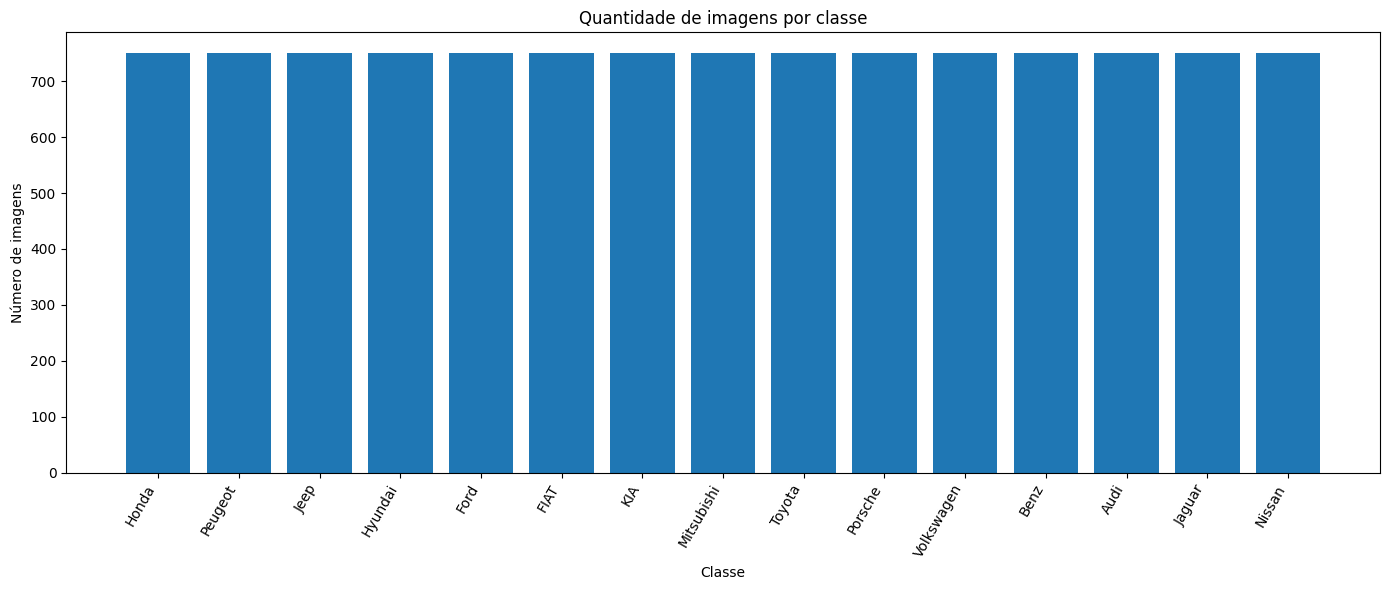

In [ ]:
# =========================
# 9) Gráfico de imagens por classe
# =========================
plt.figure(figsize=(14, 6))
plt.bar(counts_df["display_name"], counts_df["num_images"])
plt.title("Quantidade de imagens por classe")
plt.xlabel("Classe")
plt.ylabel("Número de imagens")
plt.xticks(rotation=60, ha="right")
plt.tight_layout()
plt.show()


In [ ]:
# =========================
# 10) Montar DataFrame com caminhos
# =========================
rows = []

for class_id in sorted(class_counts.keys(), key=smart_sort_key):
    class_dir = dataset_root / class_id
    display_name = folder_to_display.get(class_id, class_id)

    for img_path in list_images_from_class_folder(class_dir):
        rows.append({
            "image_path": str(img_path),
            "brand": class_id,
            "display_name": display_name
        })

df = pd.DataFrame(rows)
df = df.sample(frac=1.0, random_state=SEED).reset_index(drop=True)

display(df.head())
print(df["brand"].value_counts().sort_index())


,image_path,brand,display_name
0,/content/compcars_drive_work/image/92/754/2013...,92,Jaguar
1,/content/compcars_drive_work/image/100/248/201...,100,Honda
2,/content/compcars_drive_work/image/92/756/2013...,92,Jaguar
3,/content/compcars_drive_work/image/77/127/2014...,77,Benz
4,/content/compcars_drive_work/image/97/873/2015...,97,Nissan


brand
100    750
102    750
11     750
118    750
122    750
134    750
140    750
28     750
39     750
48     750
73     750
77     750
78     750
92     750
97     750
Name: count, dtype: int64


In [ ]:
# =========================
# 11) Split: treino / validação / teste
# =========================
train_df, temp_df = train_test_split(
    df,
    test_size=(1 - TRAIN_SIZE),
    random_state=SEED,
    stratify=df["brand"]
)

relative_test_size = TEST_SIZE / (VAL_SIZE + TEST_SIZE)

val_df, test_df = train_test_split(
    temp_df,
    test_size=relative_test_size,
    random_state=SEED,
    stratify=temp_df["brand"]
)

print("Treino:", train_df.shape)
print("Validação:", val_df.shape)
print("Teste:", test_df.shape)

print("\nDistribuição treino:")
print(train_df["display_name"].value_counts())

print("\nDistribuição validação:")
print(val_df["display_name"].value_counts())

print("\nDistribuição teste:")
print(test_df["display_name"].value_counts())


Treino: (7874, 3)
Validação: (1688, 3)
Teste: (1688, 3)

Distribuição treino:
display_name
Porsche       525
Toyota        525
Volkswagen    525
Audi          525
Honda         525
Ford          525
Benz          525
Jaguar        525
Jeep          525
Mitsubishi    525
Nissan        525
Hyundai       525
Peugeot       525
FIAT          525
KIA           524
Name: count, dtype: int64

Distribuição validação:
display_name
Audi          113
Porsche       113
Jaguar        113
Honda         113
KIA           113
Jeep          113
Volkswagen    113
FIAT          113
Peugeot       112
Hyundai       112
Benz          112
Mitsubishi    112
Toyota        112
Nissan        112
Ford          112
Name: count, dtype: int64

Distribuição teste:
display_name
Hyundai       113
Ford          113
KIA           113
Benz          113
Peugeot       113
Nissan        113
Toyota        113
Mitsubishi    113
Audi          112
Jeep          112
Honda         112
Jaguar        112
Porsche       112
FIAT       

In [ ]:
# =========================
# 12) Label encoding
# =========================
class_ids = sorted(train_df["brand"].unique(), key=smart_sort_key)
class_to_idx = {class_id: idx for idx, class_id in enumerate(class_ids)}
idx_to_class_id = {idx: class_id for class_id, idx in class_to_idx.items()}
idx_to_class_name = {
    idx: folder_to_display.get(class_id, class_id)
    for class_id, idx in class_to_idx.items()
}

train_df = train_df.copy()
val_df = val_df.copy()
test_df = test_df.copy()

train_df["label"] = train_df["brand"].map(class_to_idx)
val_df["label"]   = val_df["brand"].map(class_to_idx)
test_df["label"]  = test_df["brand"].map(class_to_idx)

num_classes = len(class_ids)
class_names_display = [idx_to_class_name[i] for i in range(num_classes)]

print("Classes finais (ids):", class_ids)
print("Classes finais (nomes):", class_names_display)
print("num_classes =", num_classes)


Classes finais (ids): ['11', '28', '39', '48', '73', '77', '78', '92', '97', '100', '102', '118', '122', '134', '140']
Classes finais (nomes): ['Jeep', 'Mitsubishi', 'Toyota', 'Porsche', 'Volkswagen', 'Benz', 'Audi', 'Jaguar', 'Nissan', 'Honda', 'Peugeot', 'Hyundai', 'Ford', 'FIAT', 'KIA']
num_classes = 15


In [ ]:
# =========================
# 13) Dataset PyTorch
# =========================
class CarBrandDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        image = Image.open(row["image_path"]).convert("RGB")
        label = int(row["label"])
        if self.transform is not None:
            image = self.transform(image)
        return image, label


In [ ]:
# =========================
# 14) Transforms + loaders
# =========================
train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomAffine(degrees=3, scale=(1.0, 1.1)),
    transforms.ColorJitter(brightness=0.1, contrast=0.1, saturation=0.1),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std =[0.229, 0.224, 0.225]),
])

eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std =[0.229, 0.224, 0.225]),
])

train_dataset = CarBrandDataset(train_df, transform=train_transform)
val_dataset   = CarBrandDataset(val_df, transform=eval_transform)
test_dataset  = CarBrandDataset(test_df, transform=eval_transform)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available())
val_loader   = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available())
test_loader  = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available())

print("Batches treino:", len(train_loader))
print("Batches val   :", len(val_loader))
print("Batches teste :", len(test_loader))


Batches treino: 493
Batches val   : 106
Batches teste : 106


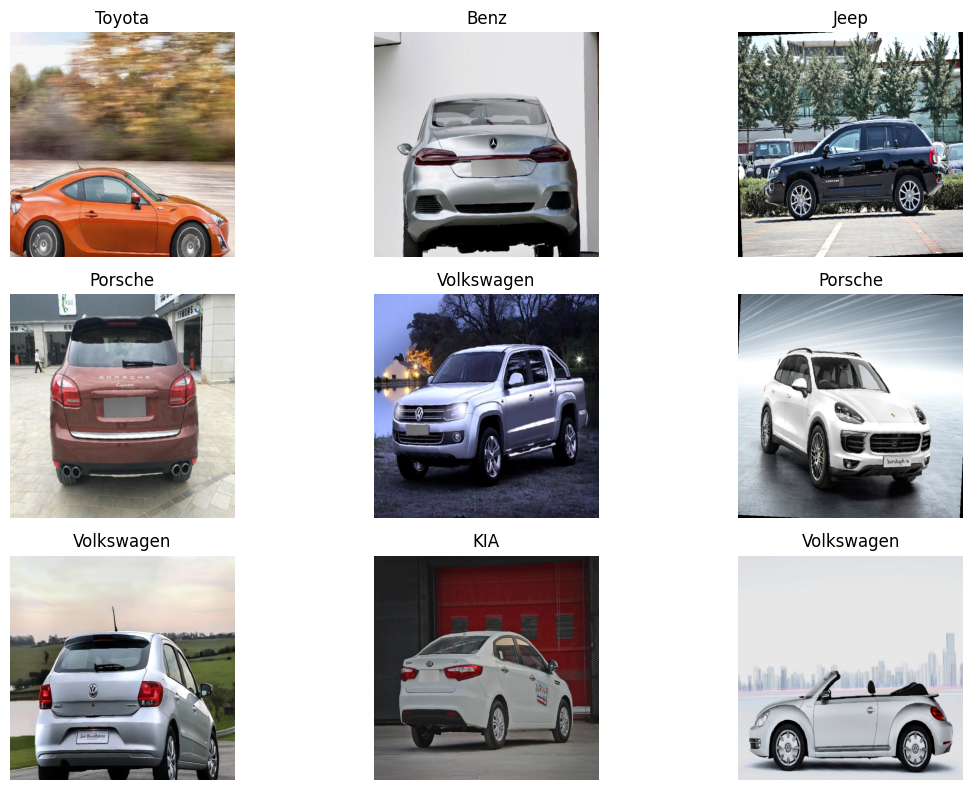

In [ ]:
# =========================
# 15) Visualização de algumas imagens
# =========================
def denormalize(img_tensor):
    mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
    std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
    return torch.clamp(img_tensor.cpu() * std + mean, 0, 1)

images, labels = next(iter(train_loader))

plt.figure(figsize=(12, 8))
for i in range(min(9, len(images))):
    plt.subplot(3, 3, i + 1)
    plt.imshow(denormalize(images[i]).permute(1, 2, 0))
    plt.title(idx_to_class_name[int(labels[i])])
    plt.axis("off")
plt.tight_layout()
plt.show()


In [ ]:
# =========================
# 16) Modelo
# =========================
model = timm.create_model(MODEL_NAME, pretrained=True, num_classes=num_classes)

if FREEZE_BACKBONE:
    for name, param in model.named_parameters():
        param.requires_grad = False

    for name, param in model.named_parameters():
        if "classifier" in name or "fc" in name or "head" in name:
            param.requires_grad = True

model = model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="min", factor=0.5, patience=2
)

print(model.__class__.__name__)


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


model.safetensors:   0%|          | 0.00/21.4M [00:00<?, ?B/s]

EfficientNet


In [ ]:
# =========================
# 17) Funções de treino e avaliação
# =========================
from tqdm.notebook import tqdm
import torch

def train_one_epoch(model, loader, criterion, optimizer, device, epoch, num_epochs):
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    pbar = tqdm(loader, desc=f"Treino {epoch+1}/{num_epochs}", leave=False)

    for images, labels in pbar:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        preds = outputs.argmax(dim=1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)

        avg_loss = running_loss / total
        avg_acc = correct / total

        pbar.set_postfix({
            "loss": f"{avg_loss:.4f}",
            "acc": f"{avg_acc:.4f}"
        })

    epoch_loss = running_loss / total
    epoch_acc = correct / total
    return epoch_loss, epoch_acc


@torch.no_grad()
def evaluate(model, loader, criterion, device, epoch, num_epochs, stage="Val"):
    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    all_preds = []
    all_labels = []

    pbar = tqdm(loader, desc=f"{stage} {epoch+1}/{num_epochs}", leave=False)

    for images, labels in pbar:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        loss = criterion(outputs, labels)

        running_loss += loss.item() * images.size(0)

        preds = outputs.argmax(dim=1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

        avg_loss = running_loss / total
        avg_acc = correct / total

        pbar.set_postfix({
            "loss": f"{avg_loss:.4f}",
            "acc": f"{avg_acc:.4f}"
        })

    epoch_loss = running_loss / total
    epoch_acc = correct / total
    return epoch_loss, epoch_acc, all_labels, all_preds

In [ ]:
# =========================
# 18) Treinamento
# =========================
history = {
    "train_loss": [],
    "train_acc": [],
    "val_loss": [],
    "val_acc": []
}

best_val_acc = -1.0
best_model_path = OUTPUT_DIR / "best_car_brand_efficientnet_b0.pth"

for epoch in range(EPOCHS):
    print(f"\n========== ÉPOCA {epoch+1}/{EPOCHS} ==========")

    train_loss, train_acc = train_one_epoch(
        model, train_loader, criterion, optimizer, device, epoch, EPOCHS
    )

    val_loss, val_acc, _, _ = evaluate(
        model, val_loader, criterion, device, epoch, EPOCHS, stage="Val"
    )

    scheduler.step(val_loss)

    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(), best_model_path)
        print(">> Melhor modelo salvo!")

    print(
        f"Época {epoch+1:02d}/{EPOCHS} | "
        f"train_loss={train_loss:.4f} | train_acc={train_acc:.4f} | "
        f"val_loss={val_loss:.4f} | val_acc={val_acc:.4f}"
    )



========== ÉPOCA 1/5 ==========


Treino 1/5:   0%|          | 0/493 [00:00<?, ?it/s]

Val 1/5:   0%|          | 0/106 [00:00<?, ?it/s]

>> Melhor modelo salvo!
Época 01/5 | train_loss=1.8060 | train_acc=0.4368 | val_loss=0.8356 | val_acc=0.7423

========== ÉPOCA 2/5 ==========


Treino 2/5:   0%|          | 0/493 [00:00<?, ?it/s]

...

Val 4/5:   0%|          | 0/106 [00:00<?, ?it/s]

>> Melhor modelo salvo!
Época 04/5 | train_loss=0.1038 | train_acc=0.9754 | val_loss=0.3169 | val_acc=0.8987

========== ÉPOCA 5/5 ==========


Treino 5/5:   0%|          | 0/493 [00:00<?, ?it/s]

Val 5/5:   0%|          | 0/106 [00:00<?, ?it/s]

>> Melhor modelo salvo!
Época 05/5 | train_loss=0.0641 | train_acc=0.9835 | val_loss=0.3366 | val_acc=0.9070


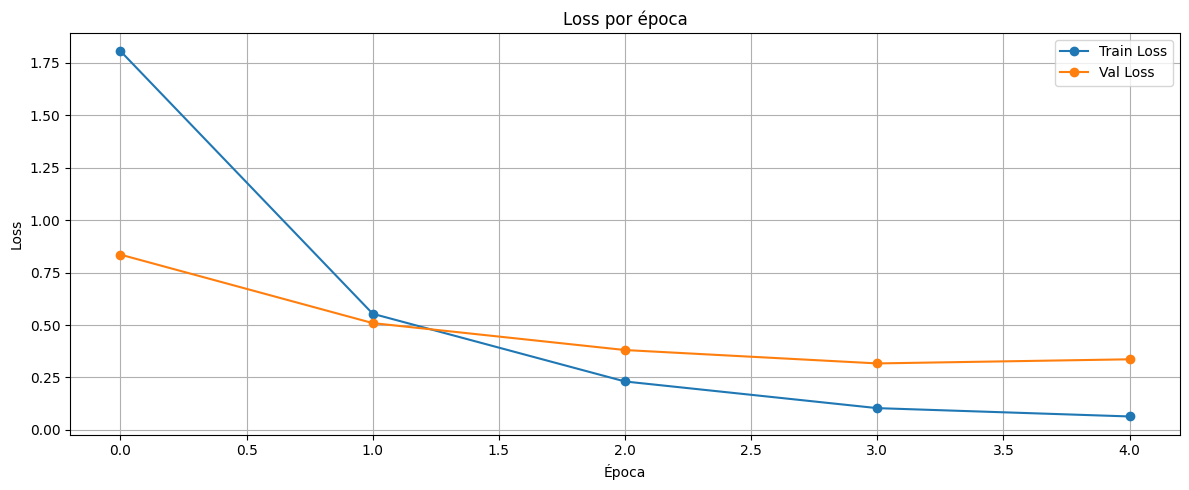

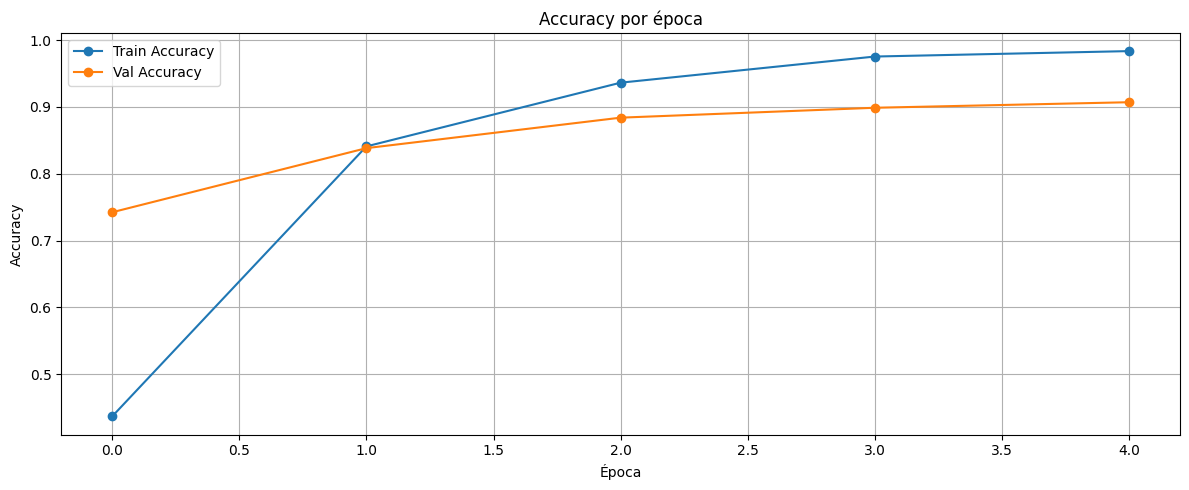

Curvas salvas em:
- /content/drive/MyDrive/projeto_p/resultados_treino_marcas_maior/loss_curve.png
- /content/drive/MyDrive/projeto_p/resultados_treino_marcas_maior/accuracy_curve.png


In [ ]:
# =========================
# 19) Curvas de treino
# =========================
history_df = pd.DataFrame(history)

plt.figure(figsize=(12, 5))
plt.plot(history["train_loss"], marker="o", label="Train Loss")
plt.plot(history["val_loss"], marker="o", label="Val Loss")
plt.title("Loss por época")
plt.xlabel("Época")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
loss_curve_path = OUTPUT_DIR / "loss_curve.png"
plt.savefig(loss_curve_path, dpi=200, bbox_inches="tight")
plt.show()

plt.figure(figsize=(12, 5))
plt.plot(history["train_acc"], marker="o", label="Train Accuracy")
plt.plot(history["val_acc"], marker="o", label="Val Accuracy")
plt.title("Accuracy por época")
plt.xlabel("Época")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.tight_layout()
acc_curve_path = OUTPUT_DIR / "accuracy_curve.png"
plt.savefig(acc_curve_path, dpi=200, bbox_inches="tight")
plt.show()

print("Curvas salvas em:")
print("-", loss_curve_path)
print("-", acc_curve_path)


In [ ]:
# =========================
# 20) Avaliação final no teste
# =========================
model.load_state_dict(torch.load(best_model_path, map_location=device))
test_loss, test_acc, y_true, y_pred = evaluate(
    model, test_loader, criterion, device, epoch=EPOCHS-1, num_epochs=EPOCHS, stage="Teste"
)

print(f"Test loss: {test_loss:.4f}")
print(f"Test acc : {test_acc:.4f}")


Teste 5/5:   0%|          | 0/106 [00:00<?, ?it/s]

Test loss: 0.3539
Test acc : 0.8981


In [ ]:
# =========================
# 21) Classification report
# =========================
report = classification_report(
    y_true,
    y_pred,
    target_names=class_names_display,
    digits=4
)

print(report)


              precision    recall  f1-score   support

        Jeep     0.9244    0.9821    0.9524       112
  Mitsubishi     0.7324    0.9204    0.8157       113
      Toyota     0.9362    0.7788    0.8502       113
     Porsche     0.9032    1.0000    0.9492       112
  Volkswagen     0.8879    0.9196    0.9035       112
        Benz     0.9279    0.9115    0.9196       113
        Audi     0.9464    0.9464    0.9464       112
      Jaguar     0.9712    0.9018    0.9352       112
      Nissan     0.9505    0.8496    0.8972       113
       Honda     0.8500    0.9107    0.8793       112
     Peugeot     0.8372    0.9558    0.8926       113
     Hyundai     0.8468    0.8319    0.8393       113
        Ford     0.8990    0.7876    0.8396       113
        FIAT     0.9806    0.9018    0.9395       112
         KIA     0.9612    0.8761    0.9167       113

    accuracy                         0.8981      1688
   macro avg     0.9037    0.8983    0.8984      1688
weighted avg     0.9036   

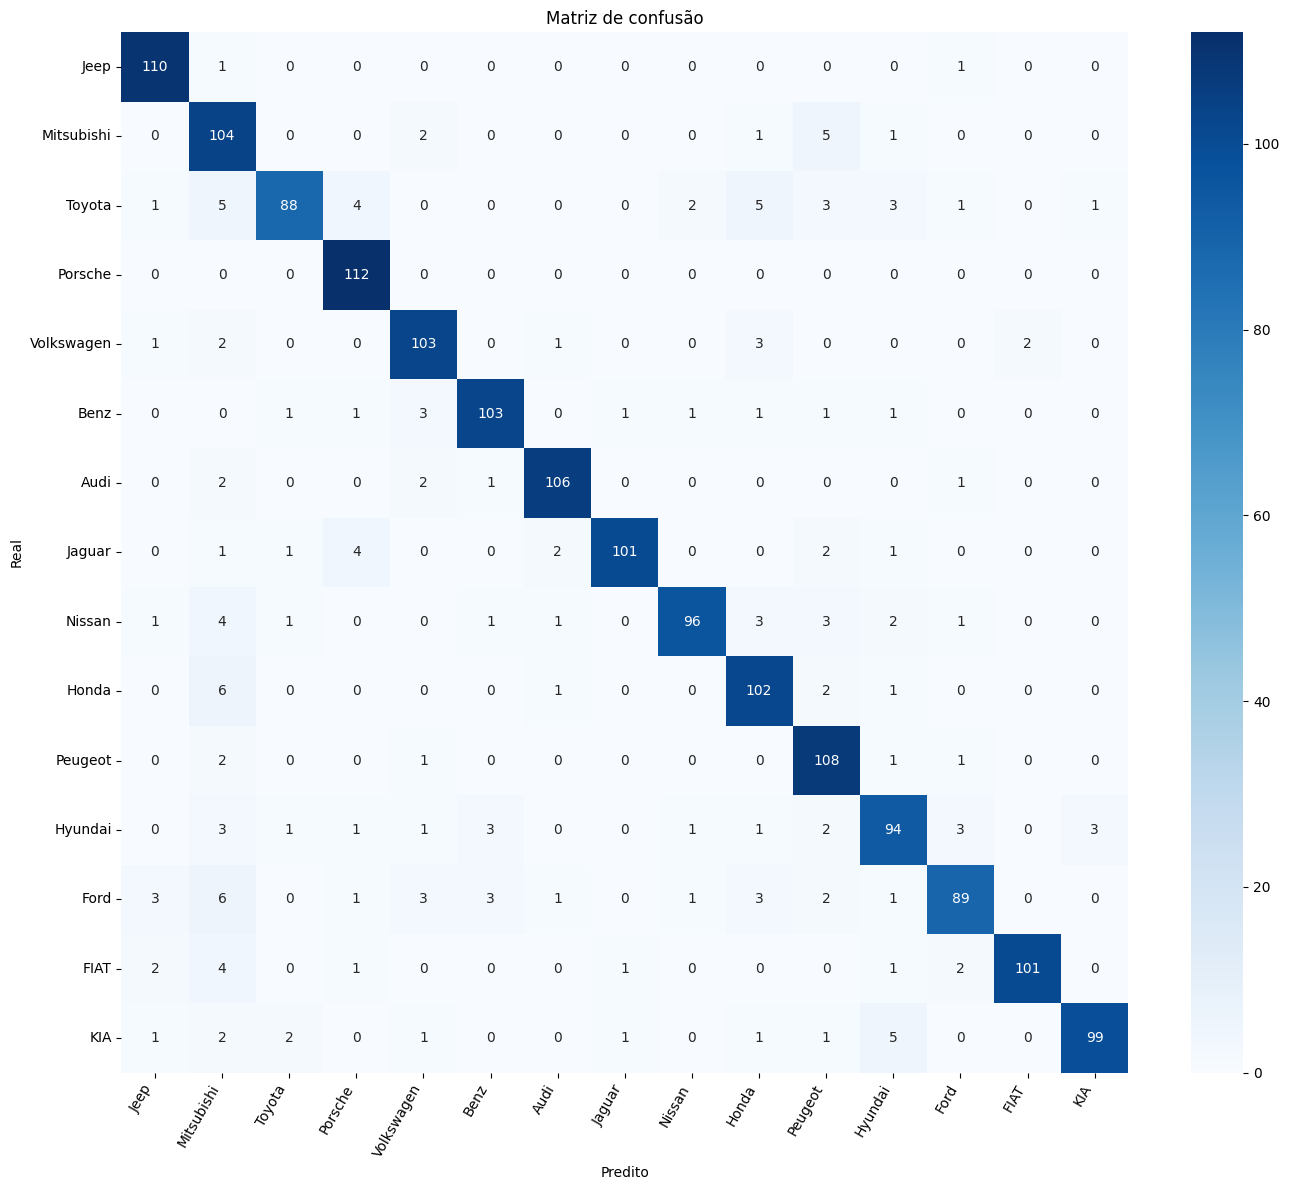

Matriz salva em: /content/drive/MyDrive/projeto_p/resultados_treino_marcas_maior/confusion_matrix.png


In [ ]:
# =========================
# 22) Matriz de confusão (valores absolutos)
# =========================
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(14, 12))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names_display,
    yticklabels=class_names_display
)
plt.xlabel("Predito")
plt.ylabel("Real")
plt.title("Matriz de confusão")
plt.xticks(rotation=60, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
cm_path = OUTPUT_DIR / "confusion_matrix.png"
plt.savefig(cm_path, dpi=200, bbox_inches="tight")
plt.show()

print("Matriz salva em:", cm_path)


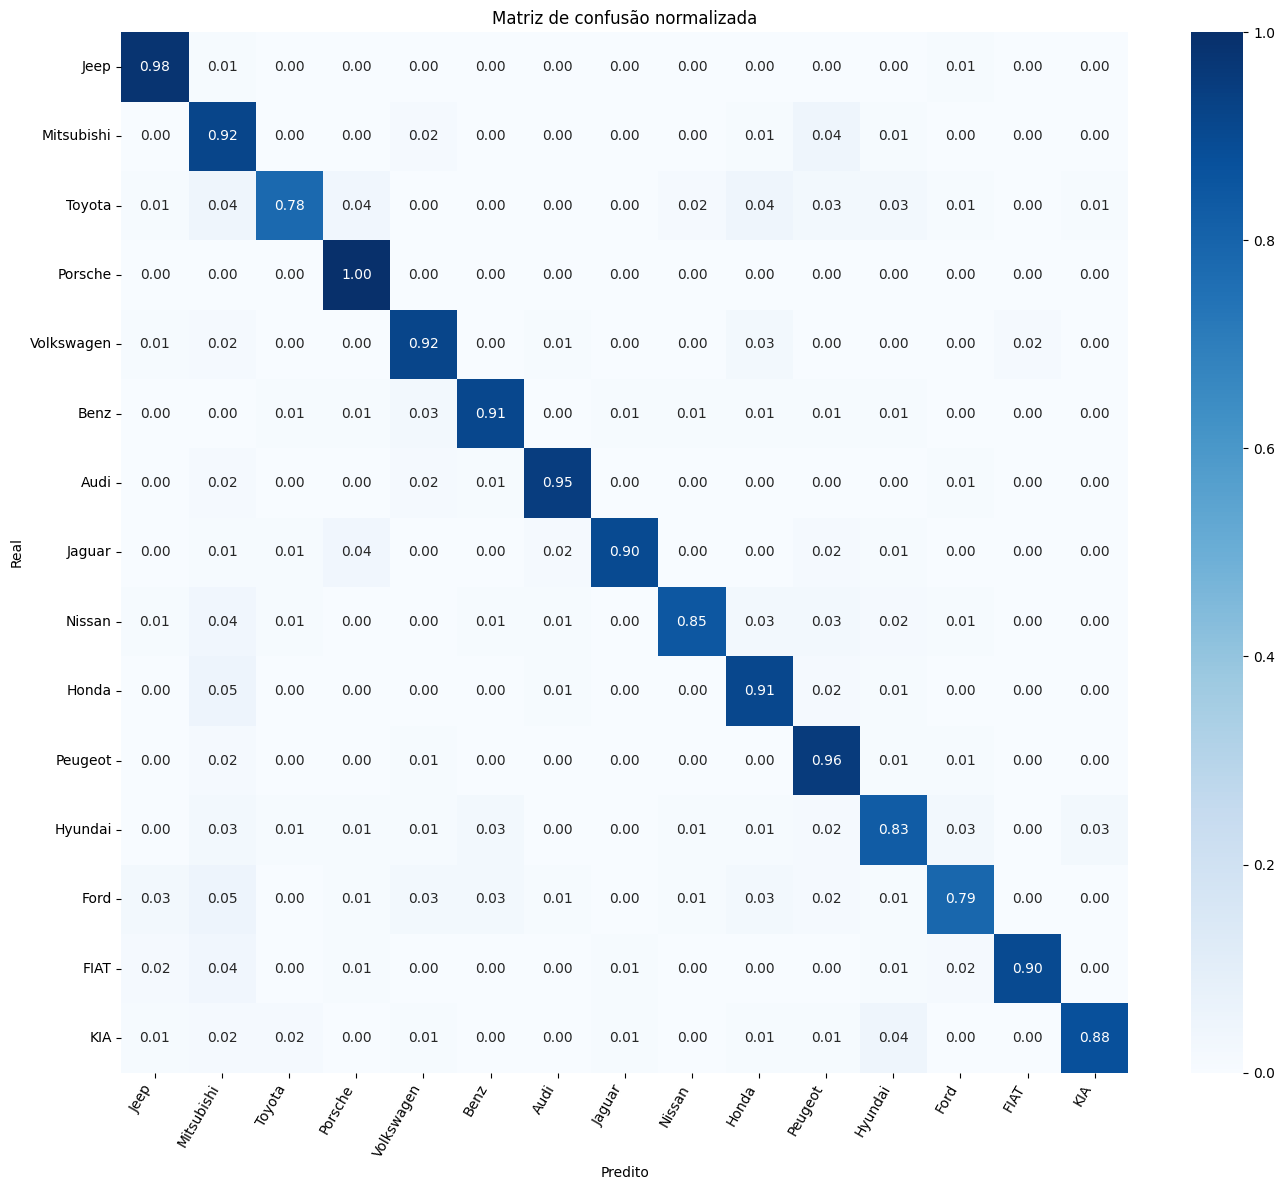

Matriz normalizada salva em: /content/drive/MyDrive/projeto_p/resultados_treino_marcas_maior/confusion_matrix_normalized.png


In [ ]:
# =========================
# 23) Matriz de confusão normalizada
# =========================
cm_norm = confusion_matrix(y_true, y_pred, normalize="true")

plt.figure(figsize=(14, 12))
sns.heatmap(
    cm_norm,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    xticklabels=class_names_display,
    yticklabels=class_names_display
)
plt.xlabel("Predito")
plt.ylabel("Real")
plt.title("Matriz de confusão normalizada")
plt.xticks(rotation=60, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
cm_norm_path = OUTPUT_DIR / "confusion_matrix_normalized.png"
plt.savefig(cm_norm_path, dpi=200, bbox_inches="tight")
plt.show()

print("Matriz normalizada salva em:", cm_norm_path)


In [ ]:
# =========================
# 24) Salvar artefatos
# =========================
history_path = OUTPUT_DIR / "history.csv"
classes_path = OUTPUT_DIR / "classes.json"
report_path  = OUTPUT_DIR / "classification_report.txt"
preds_path   = OUTPUT_DIR / "test_predictions.csv"

history_df.to_csv(history_path, index=False)

with open(classes_path, "w", encoding="utf-8") as f:
    json.dump({
        "class_ids": class_ids,
        "class_names_display": class_names_display,
        "class_to_idx": class_to_idx,
        "idx_to_class_id": idx_to_class_id,
        "idx_to_class_name": idx_to_class_name,
        "folder_to_display": folder_to_display,
    }, f, ensure_ascii=False, indent=2)

with open(report_path, "w", encoding="utf-8") as f:
    f.write(report)

pred_df = pd.DataFrame({
    "y_true_idx": y_true,
    "y_pred_idx": y_pred,
    "y_true_id": [idx_to_class_id[int(i)] for i in y_true],
    "y_pred_id": [idx_to_class_id[int(i)] for i in y_pred],
    "y_true_name": [idx_to_class_name[int(i)] for i in y_true],
    "y_pred_name": [idx_to_class_name[int(i)] for i in y_pred],
})
pred_df.to_csv(preds_path, index=False)

print("Salvo:")
print("-", history_path)
print("-", classes_path)
print("-", report_path)
print("-", preds_path)
print("-", best_model_path)
print("-", loss_curve_path)
print("-", acc_curve_path)
print("-", cm_path)
print("-", cm_norm_path)


Salvo:
- /content/drive/MyDrive/projeto_p/resultados_treino_marcas_maior/history.csv
- /content/drive/MyDrive/projeto_p/resultados_treino_marcas_maior/classes.json
- /content/drive/MyDrive/projeto_p/resultados_treino_marcas_maior/classification_report.txt
- /content/drive/MyDrive/projeto_p/resultados_treino_marcas_maior/test_predictions.csv
- /content/drive/MyDrive/projeto_p/resultados_treino_marcas_maior/best_car_brand_efficientnet_b0.pth
- /content/drive/MyDrive/projeto_p/resultados_treino_marcas_maior/loss_curve.png
- /content/drive/MyDrive/projeto_p/resultados_treino_marcas_maior/accuracy_curve.png
- /content/drive/MyDrive/projeto_p/resultados_treino_marcas_maior/confusion_matrix.png
- /content/drive/MyDrive/projeto_p/resultados_treino_marcas_maior/confusion_matrix_normalized.png


In [ ]:
# =========================
# 25) Inferência em uma imagem
# =========================
def predict_image(image_path, model, transform, idx_to_class_name, device, topk=5):
    model.eval()
    image = Image.open(image_path).convert("RGB")
    x = transform(image).unsqueeze(0).to(device)

    with torch.no_grad():
        logits = model(x)
        probs = torch.softmax(logits, dim=1)[0]
        values, indices = torch.topk(probs, k=topk)

    preds = [
        (idx_to_class_name[int(i)], float(v))
        for v, i in zip(values.cpu(), indices.cpu())
    ]
    return image, preds

# Exemplo de uso:
# example_path = test_df.iloc[0]["image_path"]
# image, preds = predict_image(example_path, model, eval_transform, idx_to_class_name, device, topk=TOPK_INFERENCE)
# plt.figure(figsize=(6, 6))
# plt.imshow(image)
# plt.axis("off")
# plt.show()
# print(preds)


# Comparação com Yolo

Por fim, resolvemos comparar o nosso modelo treinado com o Yolo (adicionando a este um Classificar de marcas).

In [ ]:
from ultralytics import YOLO
import torch
import cv2
from PIL import Image
import matplotlib.pyplot as plt

def testar_imagem(image_path):

    # =========================
    # 1) Carregar imagem
    # =========================
    image_pil = Image.open(image_path).convert("RGB")
    image_cv = cv2.imread(image_path)

    plt.figure(figsize=(6,6))
    plt.imshow(image_pil)
    plt.title("Imagem Original")
    plt.axis("off")
    plt.show()

    # =========================
    # 2) Nosso modelo
    # =========================
    model.eval()
    img_tensor = eval_transform(image_pil).unsqueeze(0).to(device)

    with torch.no_grad():
        outputs = model(img_tensor)
        probs = torch.softmax(outputs, dim=1)
        pred_class = torch.argmax(probs, dim=1).item()
        confidence = probs[0][pred_class].item()

    print("Predição do nosso modelo:")
    print("Classe:", idx_to_class_name[pred_class])
    print("Confiança:", round(confidence,4))
    pred_label = idx_to_class_name[pred_class]

    # =========================
    # 3) YOLO detecta carros
    # =========================

    yolo_model = YOLO("yolov8n.pt")
    results = yolo_model(image_path)

    boxes = results[0].boxes.xyxy.cpu().numpy()
    classes = results[0].boxes.cls.cpu().numpy()

    car_detections = []

    for box, cls in zip(boxes, classes):

        if int(cls) == 2:  # classe carro

            x1, y1, x2, y2 = map(int, box)

            crop = image_cv[y1:y2, x1:x2]

            crop_pil = Image.fromarray(cv2.cvtColor(crop, cv2.COLOR_BGR2RGB))

            tensor = eval_transform(crop_pil).unsqueeze(0).to(device)

            with torch.no_grad():
                out = model(tensor)
                probs = torch.softmax(out, dim=1)
                pred = torch.argmax(probs, dim=1).item()
                conf = probs[0][pred].item()

            label = idx_to_class_name[pred]

            car_detections.append((x1, y1, x2, y2, label, conf))

    # =========================
    # 4) Desenhar bounding boxes
    # =========================
    image_draw = image_cv.copy()

    for x1, y1, x2, y2, label, conf in car_detections:

        text = f"{label} {conf:.2f}"

        cv2.rectangle(image_draw, (x1,y1), (x2,y2), (0,255,0), 2)

        cv2.putText(
            image_draw,
            text,
            (x1, y1-10),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.7,
            (0,255,0),
            2
        )

    # =========================
    # 5) Comparação
    # =========================
    fig, axes = plt.subplots(1,2, figsize=(14,6))

    axes[0].imshow(image_pil)
    axes[0].set_title(
        f"Meu Modelo\n{pred_label}\nConf: {confidence:.2f}"
    )
    axes[0].axis("off")

    axes[1].imshow(cv2.cvtColor(image_draw, cv2.COLOR_BGR2RGB))
    axes[1].set_title(
        f"YOLO + Classificador\nCarros detectados: {len(car_detections)}"
    )
    axes[1].axis("off")

    plt.tight_layout()
    plt.show()

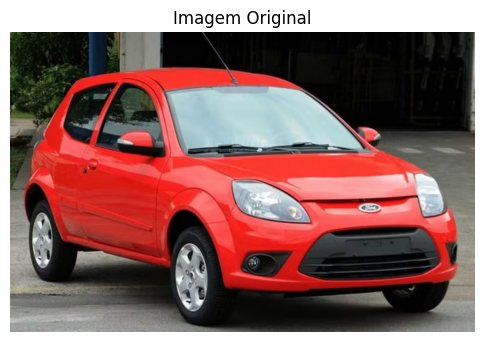

Predição do nosso modelo:
Classe: Ford
Confiança: 0.9988

image 1/1 /content/drive/MyDrive/projeto_p/teste.jpg: 416x640 1 car, 185.5ms
Speed: 14.5ms preprocess, 185.5ms inference, 85.3ms postprocess per image at shape (1, 3, 416, 640)


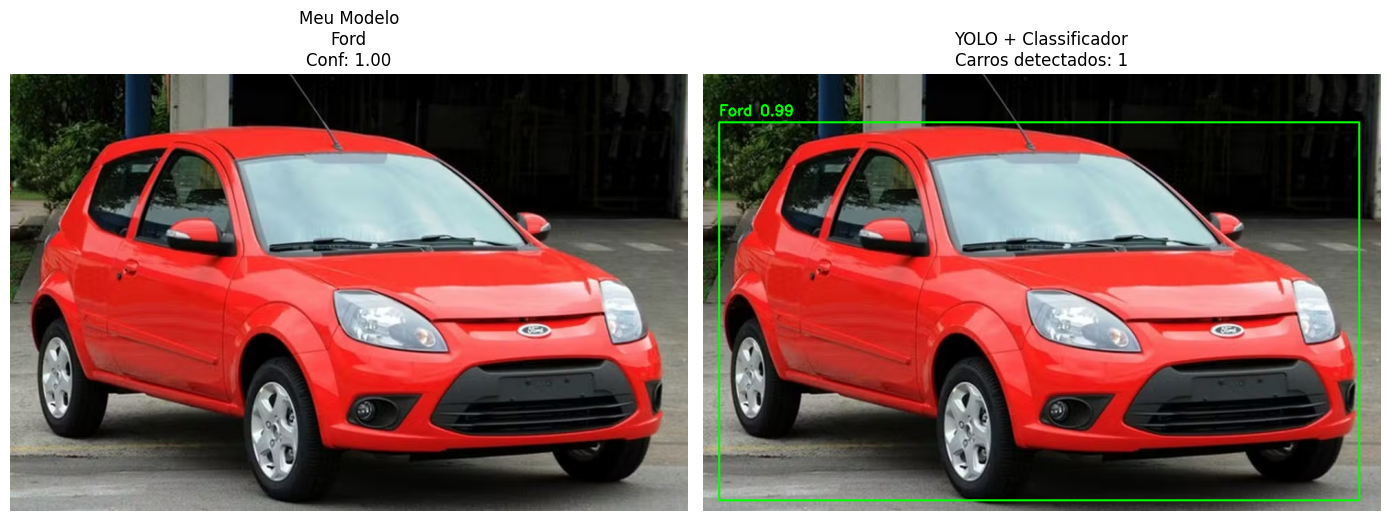

In [ ]:
testar_imagem("/content/drive/MyDrive/projeto_p/teste.jpg")

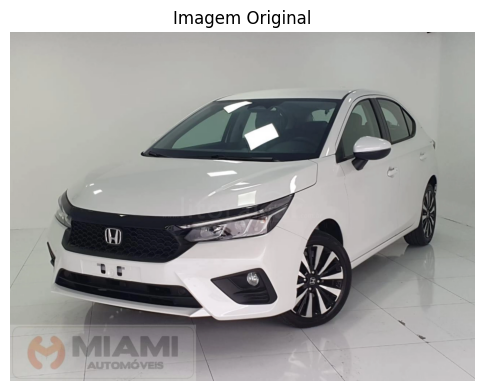

Predição do nosso modelo:
Classe: Honda
Confiança: 0.9998

image 1/1 /content/drive/MyDrive/projeto_p/honda.jpg: 480x640 1 car, 107.5ms
Speed: 3.8ms preprocess, 107.5ms inference, 2.1ms postprocess per image at shape (1, 3, 480, 640)


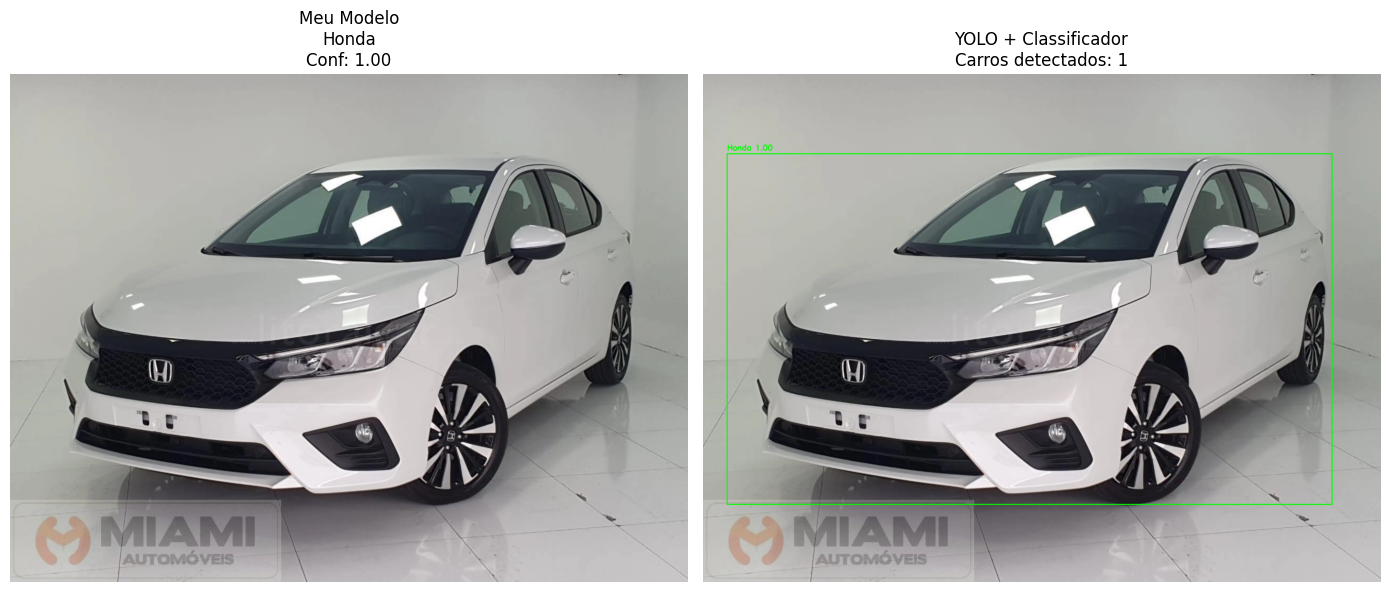

In [ ]:
testar_imagem("/content/drive/MyDrive/projeto_p/honda.jpg")

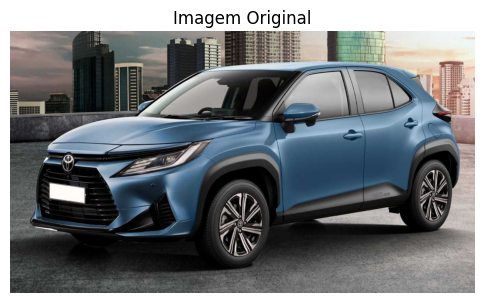

Predição do nosso modelo:
Classe: Volkswagen
Confiança: 0.6371

image 1/1 /content/drive/MyDrive/projeto_p/toyota.jpg: 384x640 1 car, 1 truck, 104.0ms
Speed: 3.7ms preprocess, 104.0ms inference, 4.3ms postprocess per image at shape (1, 3, 384, 640)


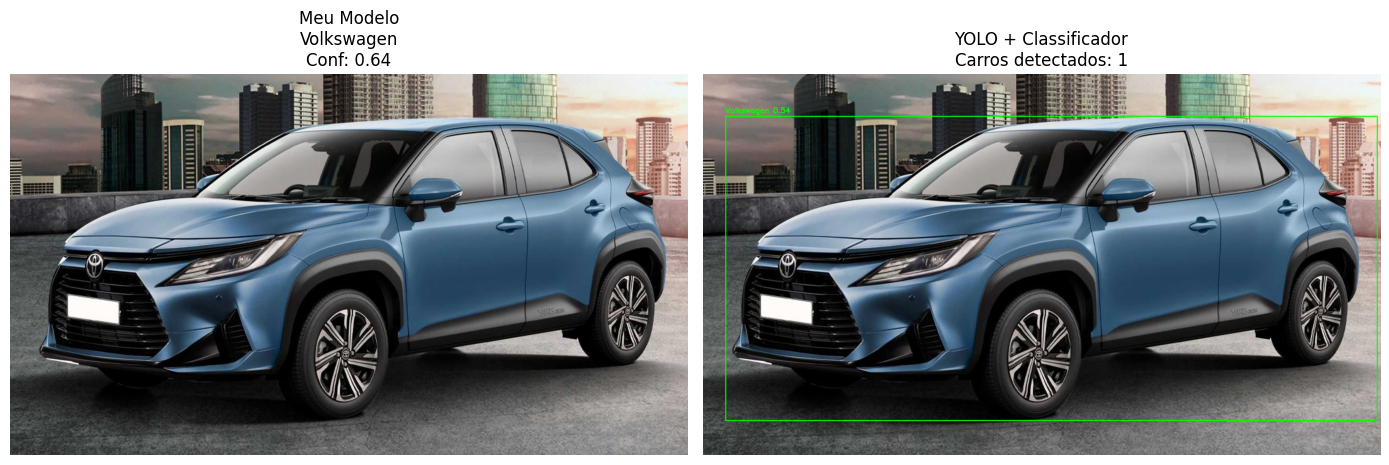

In [ ]:
testar_imagem("/content/drive/MyDrive/projeto_p/toyota.jpg")

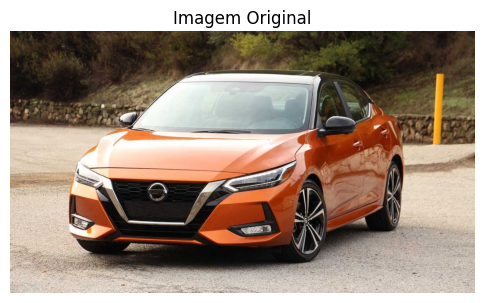

Predição do nosso modelo:
Classe: Nissan
Confiança: 0.9359

image 1/1 /content/drive/MyDrive/projeto_p/nissan.jpg: 384x640 1 car, 12.2ms
Speed: 2.2ms preprocess, 12.2ms inference, 1.9ms postprocess per image at shape (1, 3, 384, 640)


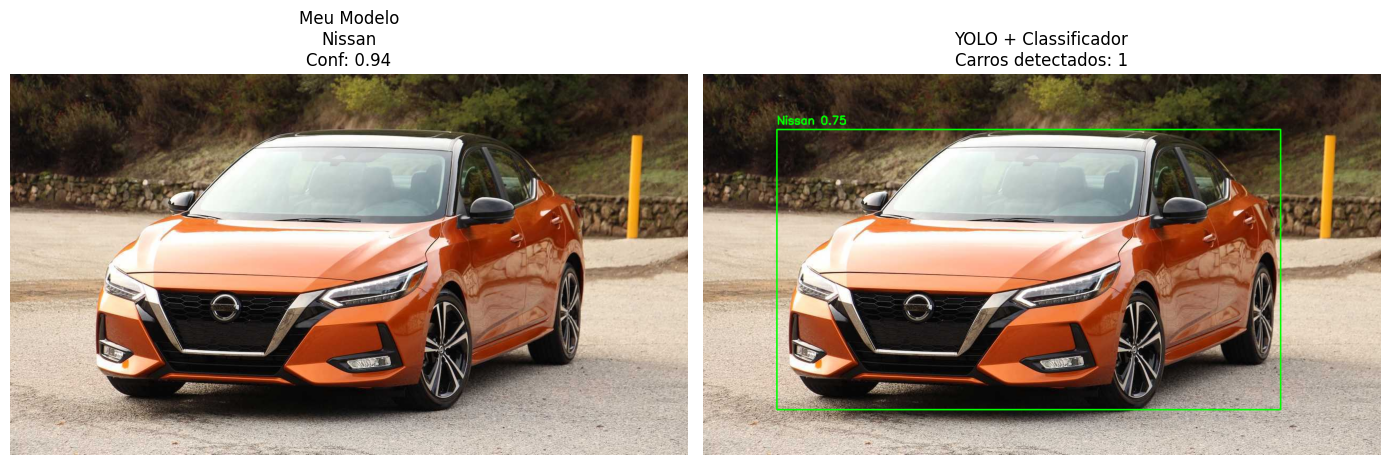

In [ ]:
testar_imagem("/content/drive/MyDrive/projeto_p/nissan.jpg")

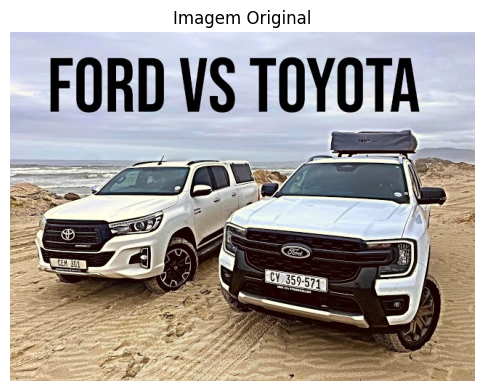

Predição do nosso modelo:
Classe: Ford
Confiança: 0.7348

image 1/1 /content/drive/MyDrive/projeto_p/fordXtoyota.jpg: 480x640 2 cars, 1 suitcase, 7.1ms
Speed: 1.2ms preprocess, 7.1ms inference, 4.2ms postprocess per image at shape (1, 3, 480, 640)


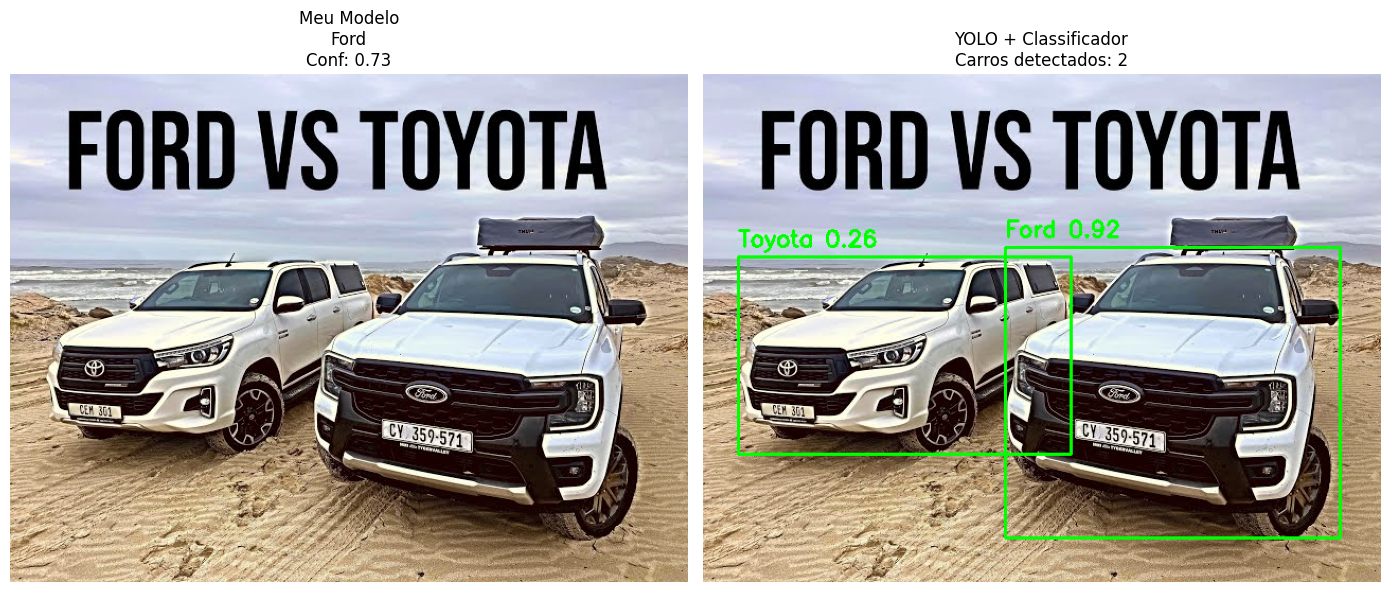

In [ ]:
testar_imagem("/content/drive/MyDrive/projeto_p/fordXtoyota.jpg")